# IPL 2022 Capstone Project
### The Indian Premier League (IPL) is a professional T20 cricket league in India, featuring franchises representing cities. This project explores IPL 2022 match-level data to derive meaningful insights and understand match outcomes, player performances, and team dynamics.

### These are some of the important columns that we'll focus on for meaningful insights in this project.

### column names: Variable Type

* date : string
* venue : string
* stage : string
* team1 : string
* team2 : string
* toss_winner : string
* toss_decision : string
* first_ings_score : integer
* second_ings_score : integer
* match_winner : string
* won_by : string
* margin : integer
* player_of_the_match : string
* top_scorer : string
* highscore : integer
* best_bowling : string
* best_bowling_fgure : string
* gure : string

## Loading the libraries and Dataset

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
csv_path = next((p for p in [Path('IPL.csv'), Path('Nassau Candy Distributor.csv')] if p.exists()), Path('IPL.csv'))
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()
df.columns = [c.lower().replace(' ', '_') for c in df.columns]
df.head()

,match_id,date,venue,stage,team1,team2,toss_winner,toss_decision,first_ings_score,second_ings_score,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,2022-03-26,Mumbai,League,CSK,KKR,KKR,field,178,182,KKR,Runs,4,Andre Russell,Shubman Gill,85,Varun Chakravarthy,4--26
1,2,2022-03-27,Delhi,League,RCB,PBKS,RCB,field,191,188,RCB,Runs,3,Glenn Maxwell,Ruturaj Gaikwad,82,Harshal Patel,3--21
2,3,2022-03-28,Chennai,League,MI,GT,GT,field,178,181,GT,Wickets,4,Hardik Pandya,David Miller,77,Lockie Ferguson,3--18
3,4,2022-03-29,Bengaluru,League,RR,LSG,RR,bat,177,174,RR,Runs,3,Jos Buttler,Jos Buttler,95,Bumrah,2--24
4,5,2022-04-01,Mumbai,League,KKR,RCB,RCB,bat,169,172,RCB,Wickets,5,Faf du Plessis,Faf du Plessis,88,Harshal Patel,4--22


In [5]:
df = pd.read_csv(r"C:\Users\DEEPAK DALAI\OneDrive\app1\GITHUB\IPL Capstion.project\IPL.csv")

### Basic Information

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   match_id             20 non-null     int64
 1   date                 20 non-null     str  
 2   venue                20 non-null     str  
 3   stage                20 non-null     str  
 4   team1                20 non-null     str  
 5   team2                20 non-null     str  
 6   toss_winner          20 non-null     str  
 7   toss_decision        20 non-null     str  
 8   first_ings_score     20 non-null     int64
 9   second_ings_score    20 non-null     int64
 10  match_winner         20 non-null     str  
 11  won_by               20 non-null     str  
 12  margin               20 non-null     int64
 13  player_of_the_match  20 non-null     str  
 14  top_scorer           20 non-null     str  
 15  highscore            20 non-null     int64
 16  best_bowling         20 non-null     st

##### Check the size of rows and columns of the dataset


In [7]:
print(f"your rows are {df.shape[0]} and your columns are {df.shape[1]}")

your rows are 20 and your columns are 18


##### Now let's see how many columns have null values in total

In [8]:
df.isnull().sum()

match_id               0
date                   0
venue                  0
stage                  0
team1                  0
team2                  0
toss_winner            0
toss_decision          0
first_ings_score       0
second_ings_score      0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

##### Now,Here comes some Basic Questions

##### 1.Which won the most matches?

Text(0.5, 1.0, 'Most match win by team')

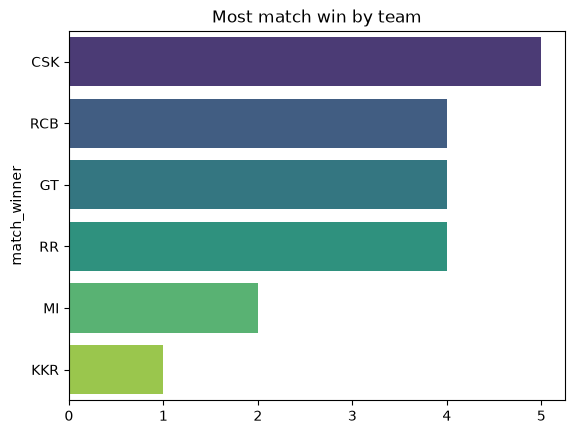

In [9]:
match_wins = df['match_winner'].value_counts()
sns.barplot(y=match_wins.index,x=match_wins.values,palette = 'viridis')
plt.title('Most match win by team')

##### 2.Toss Decision Trends


Text(0.5, 1.0, 'Toss Descision Trends ')

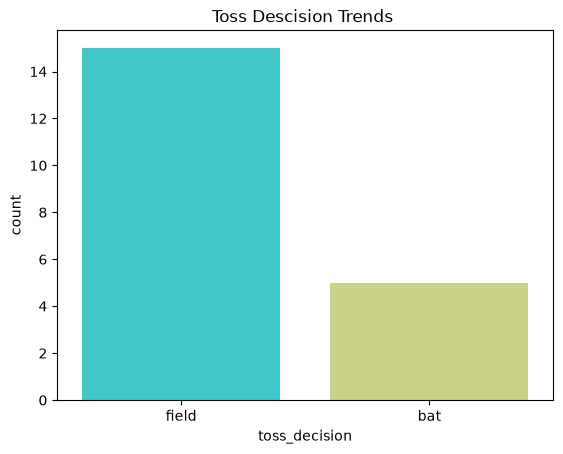

In [10]:
sns.countplot(x = df['toss_decision'], palette = 'rainbow')
plt.title("Toss Descision Trends ")

##### 3.Toss Winner vs Match Winner

In [11]:
count = df[df["toss_winner"]==df["match_winner"]]['match_id'].count()
percentage = (count*100)/df.shape[0]
percentage.round(2)

np.float64(95.0)

##### 4.How do teams win?(Runs vs Wicket)

Text(0.5, 1.0, 'Won by')

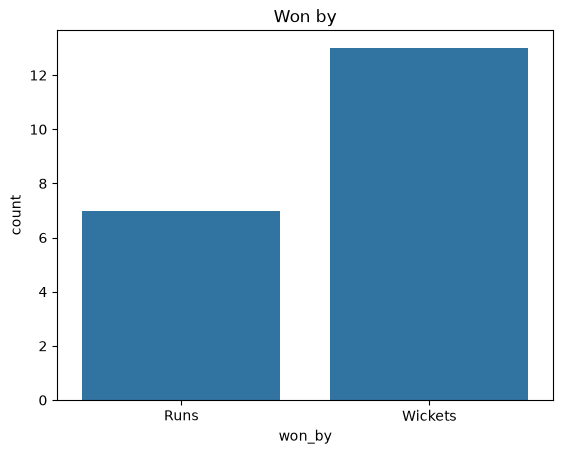

In [12]:
sns.countplot(x=df['won_by'])
plt.title("Won by")

### Key Player Performances

##### 1.Most "player of The Match" Awards

In [13]:
count = df['player_of_the_match'].value_counts().head(10)
count

player_of_the_match
Glenn Maxwell       2
Jos Buttler         2
Sanju Samson        2
Ruturaj Gaikwad     2
MS Dhoni            2
Shubman Gill        2
Andre Russell       1
Hardik Pandya       1
Faf du Plessis      1
Suryakumar Yadav    1
Name: count, dtype: int64

Text(0.5, 1.0, 'Top 10 plyer of the match ')

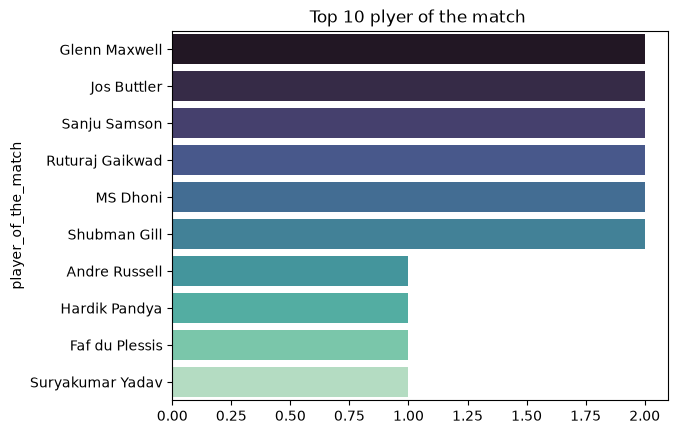

In [14]:
sns.barplot(x=count.values , y =count.index,palette = 'mako'  )
plt.title("Top 10 plyer of the match ")

##### 2.2Top Score

In [15]:
high = df.groupby('top_scorer')['highscore'].sum().sort_values(ascending = False).head(2)
high

top_scorer
Shubman Gill       284
Ruturaj Gaikwad    280
Name: highscore, dtype: int64

<Axes: ylabel='top_scorer'>

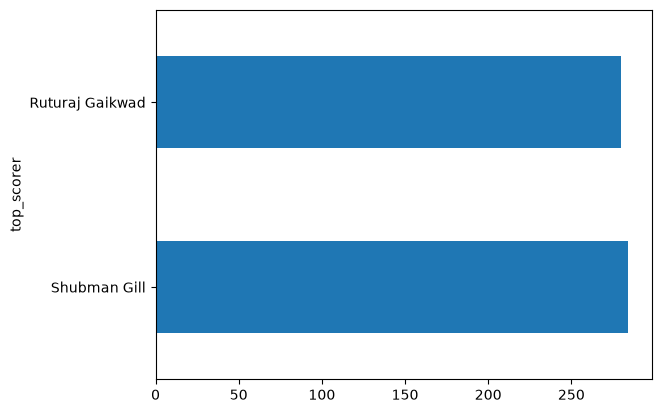

In [16]:
high.plot(kind = 'barh')

##### 10 Best bowilig Figures

In [17]:
df.head()

,match_id,date,venue,stage,team1,team2,toss_winner,toss_decision,first_ings_score,second_ings_score,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,2022-03-26,Mumbai,League,CSK,KKR,KKR,field,178,182,KKR,Runs,4,Andre Russell,Shubman Gill,85,Varun Chakravarthy,4--26
1,2,2022-03-27,Delhi,League,RCB,PBKS,RCB,field,191,188,RCB,Runs,3,Glenn Maxwell,Ruturaj Gaikwad,82,Harshal Patel,3--21
2,3,2022-03-28,Chennai,League,MI,GT,GT,field,178,181,GT,Wickets,4,Hardik Pandya,David Miller,77,Lockie Ferguson,3--18
3,4,2022-03-29,Bengaluru,League,RR,LSG,RR,bat,177,174,RR,Runs,3,Jos Buttler,Jos Buttler,95,Bumrah,2--24
4,5,2022-04-01,Mumbai,League,KKR,RCB,RCB,bat,169,172,RCB,Wickets,5,Faf du Plessis,Faf du Plessis,88,Harshal Patel,4--22


In [18]:
if 'best_bowling_figure' in df.columns:
    df['higest_wicket'] = df['best_bowling_figure'].map(lambda x: str(x).split('--')[0].split('/')[0].strip() if pd.notna(x) else 0)
    df['higest_wicket'] = pd.to_numeric(df['higest_wicket'], errors='coerce').fillna(0).astype(int)
top_bowlers = df.groupby('best_bowling')['higest_wicket'].sum().sort_values(ascending=False).head(10)
top_bowlers

best_bowling
Harshal Patel         14
Deepak Chahar          7
Rashid Khan            7
Lockie Ferguson        6
Trent Boult            5
Varun Chakravarthy     4
Prasidh Krishna        3
 Rashid Khan           3
Jasprit Bumrah         3
Maheesh Theekshana     3
Name: higest_wicket, dtype: int64

<Axes: ylabel='player_of_the_match'>

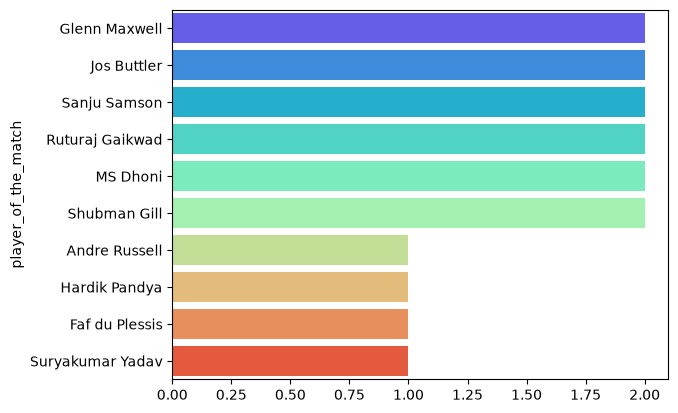

In [19]:
sns.barplot(x = count.values,y=count.index,palette = 'rainbow')

### Venu Analysis

##### most matches played by Venue

In [20]:
value_count = df['venue'].value_counts().head()
value_count

venue
Mumbai       5
Delhi        4
Chennai      4
Ahmedabad    3
Bengaluru    2
Name: count, dtype: int64

<Axes: ylabel='venue'>

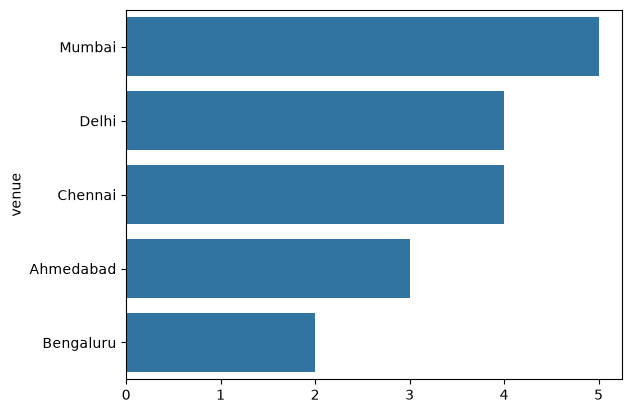

In [21]:
sns.barplot(y = value_count.index,x=value_count.values)


In [22]:
df.head()

,match_id,date,venue,stage,team1,team2,toss_winner,toss_decision,first_ings_score,second_ings_score,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,higest_wicket
0,1,2022-03-26,Mumbai,League,CSK,KKR,KKR,field,178,182,KKR,Runs,4,Andre Russell,Shubman Gill,85,Varun Chakravarthy,4--26,4
1,2,2022-03-27,Delhi,League,RCB,PBKS,RCB,field,191,188,RCB,Runs,3,Glenn Maxwell,Ruturaj Gaikwad,82,Harshal Patel,3--21,3
2,3,2022-03-28,Chennai,League,MI,GT,GT,field,178,181,GT,Wickets,4,Hardik Pandya,David Miller,77,Lockie Ferguson,3--18,3
3,4,2022-03-29,Bengaluru,League,RR,LSG,RR,bat,177,174,RR,Runs,3,Jos Buttler,Jos Buttler,95,Bumrah,2--24,2
4,5,2022-04-01,Mumbai,League,KKR,RCB,RCB,bat,169,172,RCB,Wickets,5,Faf du Plessis,Faf du Plessis,88,Harshal Patel,4--22,4


### Custom Questions & insights

##### Q1.Who won the hidest margin by runs?

In [23]:
df[df['won_by']== 'Runs'].sort_values(by='margin',ascending=False).head(1)[['match_winner','margin']]

,match_winner,margin
0,KKR,4


##### Q2.Which player had the hidest individual score?


In [24]:
df[df['highscore']==df['highscore'].max()][['top_scorer','highscore']]

,top_scorer,highscore
9,Shubman Gill,103


##### Q3.Which bowler had the best bowling figures?

In [25]:
df[df['higest_wicket'] == df['higest_wicket'].max()][['best_bowling','best_bowling_figure']]

,best_bowling,best_bowling_figure
0,Varun Chakravarthy,4--26
4,Harshal Patel,4--22
7,Deepak Chahar,4--27
12,Harshal Patel,4--26
14,Rashid Khan,4--24
